# NLTK book: selected exercises

These are small adaptations of the vocabulary, frequency, text-search, and
word-filtering exercises in [Chapter 1 of the NLTK book](https://www.nltk.org/book/ch01.html).
They use the bundled public-domain Austen texts rather than downloading
every corpus in `nltk.book`. The assignment is exploratory and ungraded;
this notebook records exercises actually run.

In [1]:
from pathlib import Path
import nltk
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from nltk import FreqDist, Text, bigrams
from nltk.corpus import gutenberg, stopwords

nltk.data.path.insert(0, str(Path('../data/nltk_data').resolve()))
records = []
for name in ['austen-emma.txt', 'austen-sense.txt']:
    tokens = gutenberg.words(name)
    words = [token.casefold() for token in tokens if token.isalpha()]
    records.append({'corpus': name, 'tokens_including_punctuation': len(tokens),
                    'word_tokens': len(words), 'word_types': len(set(words)),
                    'type_token_ratio': len(set(words)) / len(words)})
display(pd.DataFrame(records))
assert all(0 < record['type_token_ratio'] < 1 for record in records)

,corpus,tokens_including_punctuation,word_tokens,word_types,type_token_ratio
0,austen-emma.txt,192427,161600,7079,0.043806
1,austen-sense.txt,141576,120733,6283,0.052040


## Frequency and percentage exercises

Count alphabetic words case-insensitively. Token frequency includes
repetitions; vocabulary size counts distinct forms. Type/token ratios depend
on text length and preprocessing, so these two values are not a controlled
test of an author's vocabulary.

In [2]:
tokens = list(gutenberg.words('austen-emma.txt'))
words = [token.casefold() for token in tokens if token.isalpha()]
frequencies = FreqDist(words)
print('Most common words:', frequencies.most_common(15))
print('Percentage of the:', round(100 * frequencies['the'] / len(words), 3))
print('Words ending in ing, first 20:', sorted({word for word in words if word.endswith('ing')})[:20])
print('Words over 12 letters, first 20:', sorted({word for word in words if len(word) > 12})[:20])
assert sum(frequencies.values()) == len(words)
assert frequencies['the'] > frequencies['marriage'] > 0

Most common words: [('to', 5239), ('the', 5201), ('and', 4896), ('of', 4291), ('i', 3178), ('a', 3129), ('it', 2528), ('her', 2469), ('was', 2398), ('she', 2340), ('in', 2188), ('not', 2140), ('you', 1980), ('be', 1975), ('that', 1806)]
Percentage of the: 3.218
Words ending in ing, first 20: ['absenting', 'absorbing', 'abusing', 'accepting', 'accompanying', 'according', 'accounting', 'acknowledging', 'acting', 'adding', 'addressing', 'adjoining', 'admiring', 'adoring', 'advancing', 'adventuring', 'advertising', 'advising', 'affecting', 'affording']
Words over 12 letters, first 20: ['accommodation', 'accommodations', 'accompaniment', 'accomplishment', 'accomplishments', 'accumulations', 'acknowledging', 'acknowledgment', 'acknowledgments', 'affectionately', 'agreeableness', 'alphabetically', 'apprehensively', 'argumentative', 'astonishingly', 'awkwardnesses', 'characteristic', 'cheerlessness', 'churchwardens', 'circumspection']


In [3]:
text = Text(tokens)
text.concordance('marriage', width=90, lines=5)
print('First Emma position:', text.index('Emma'))
print('First Emma context:', tokens[max(0, text.index('Emma') - 3):text.index('Emma') + 6])
stop = set(stopwords.words('english'))
content_pairs = FreqDist((left, right) for left, right in bigrams(words)
                         if left not in stop and right not in stop)
print('Frequent adjacent content bigrams:', content_pairs.most_common(10))
# Count adjacent original words; removing stopwords first would invent pairs.
assert content_pairs[('mr', 'knightley')] > 0

Displaying 5 of 35 matches:
d had , in consequence of her sister ' s marriage , been mistress of his house from a very
rve which had soon followed Isabella ' s marriage , on their being left to each other , wa
 suppose it ; but she knows how much the marriage is to Miss Taylor ' s advantage ; she kn
 the last four years to bring about this marriage . A worthy employment for a young lady '
tate -- was not to be dissuaded from the marriage , and it took place , to the infinite mo
First Emma position: 1
First Emma context: ['[', 'Emma', 'by', 'Jane', 'Austen', '1816', ']']
Frequent adjacent content bigrams: [(('mr', 'knightley'), 299), (('mrs', 'weston'), 256), (('mr', 'elton'), 229), (('miss', 'woodhouse'), 173), (('mr', 'weston'), 167), (('frank', 'churchill'), 151), (('mrs', 'elton'), 150), (('mr', 'woodhouse'), 135), (('every', 'thing'), 126), (('miss', 'fairfax'), 125)]


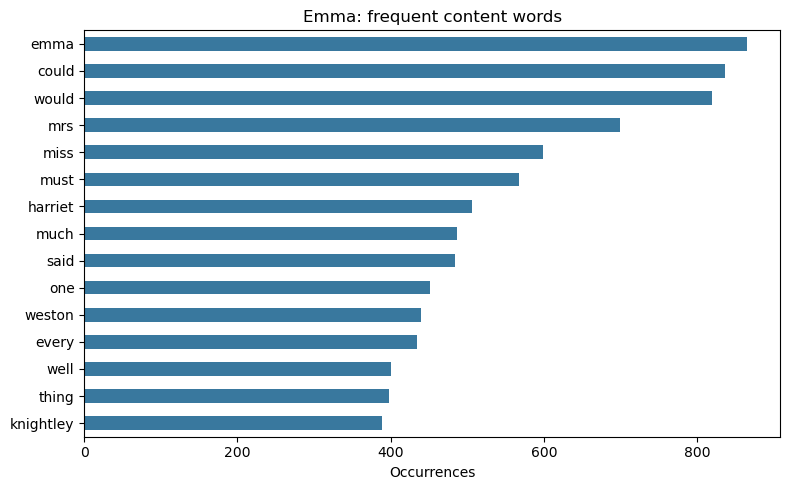

Completed: token/type counts, lexical diversity, frequency percentages, suffix/length filters, concordance, and bigrams.


In [4]:
content = FreqDist(word for word in words if word not in stop and len(word) > 2)
series = pd.Series(dict(content.most_common(15))).sort_values()
ax = series.plot.barh(figsize=(8, 5), color='#39789e', title='Emma: frequent content words')
ax.set_xlabel('Occurrences')
plt.tight_layout()
plt.savefig('nltk-frequencies.png', dpi=160)
plt.show()
print('Completed: token/type counts, lexical diversity, frequency percentages, suffix/length filters, concordance, and bigrams.')